Device: cuda
Reference data shape: (1000, 2)

Starting PINN training...

Epoch    1/1500 | Data Loss: 0.889961 | ODE Loss: 24.323925
Estimated K: [0.1198801 0.0015015 0.02997   0.0003003]
Epoch  250/1500 | Data Loss: 0.152390 | ODE Loss: 0.105539
Estimated K: [0.1063875 0.0016868 0.028208  0.0003104]
Epoch  500/1500 | Data Loss: 0.060398 | ODE Loss: 0.009212
Estimated K: [0.1013103 0.0017931 0.0272754 0.0003234]
Epoch  750/1500 | Data Loss: 0.036031 | ODE Loss: 0.003967
Estimated K: [0.0982002 0.0018758 0.0263944 0.0003401]
Epoch 1000/1500 | Data Loss: 0.026279 | ODE Loss: 0.003021
Estimated K: [0.0966784 0.0019216 0.0259862 0.0003488]
Epoch 1250/1500 | Data Loss: 0.018270 | ODE Loss: 0.002014
Estimated K: [0.0951204 0.0019724 0.0255953 0.0003578]
Epoch 1500/1500 | Data Loss: 0.012200 | ODE Loss: 0.001232
Estimated K: [0.0935887 0.0020266 0.0252433 0.0003663]

Training completed.

INVERSE PROBLEM RESULTS
-----------------------------------------------------------------
Parameter       

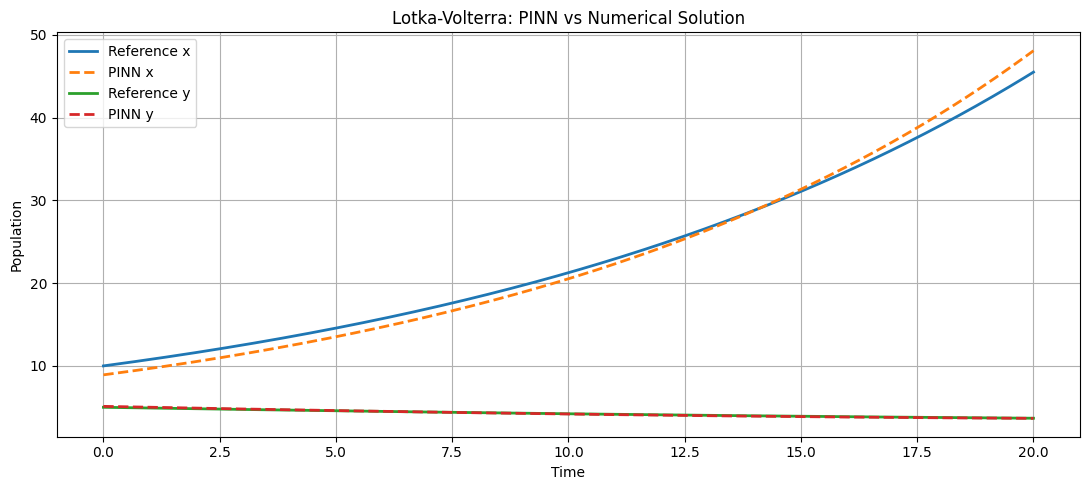

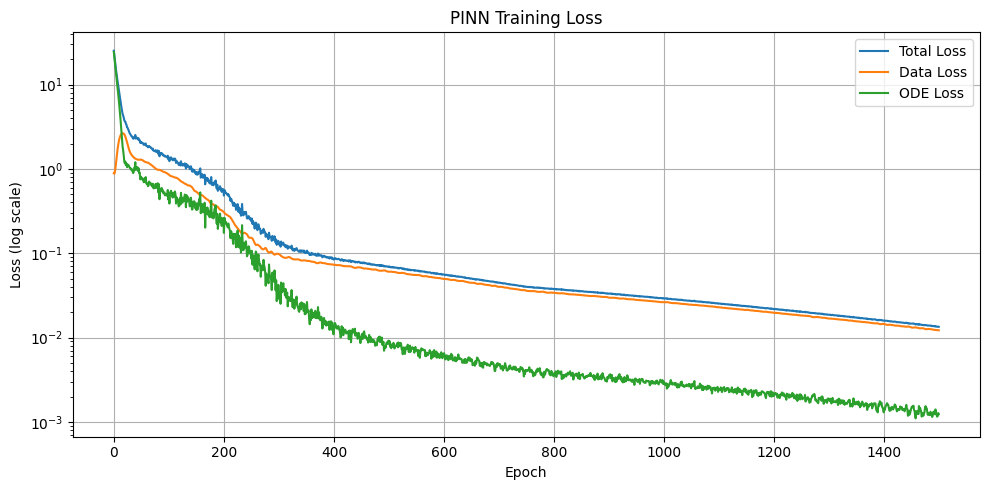


Finished.


In [ ]:

# LOTKA-VOLTERRA PINN: CORRECTED FORWARD + INVERSE EXAMPLE

import torch
import torch.nn as nn
import numpy as np
import matplotlib.pyplot as plt

from torch.autograd import grad
from scipy.integrate import solve_ivp

# 1. SETTINGS

SEED = 0
EPOCHS = 1500
N_OBS = 600
N_COLLOCATION = 256
LEARNING_RATE = 1e-3

torch.manual_seed(SEED)
np.random.seed(SEED)

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

# 2. LOTKA-VOLTERRA ODE SYSTEM

def lotka_volterra(t, z, alpha, beta, delta, gamma):
    x, y = z

    dxdt = alpha * x - beta * x * y
    dydt = -delta * y + gamma * x * y

    return [dxdt, dydt]


# 3. GENERATE REFERENCE DATA

K_true = np.array(
    [0.08, 0.001, 0.02, 0.0002],
    dtype=np.float64
)

parameter_names = ["alpha", "beta", "delta", "gamma"]

t_start = 0.0
t_end = 20.0
time_scale = t_end - t_start

z0 = [10.0, 5.0]

t_eval = np.linspace(t_start, t_end, 1000)

solution = solve_ivp(
    fun=lambda t, z: lotka_volterra(t, z, *K_true),
    t_span=(t_start, t_end),
    y0=z0,
    t_eval=t_eval,
    method="DOP853",
    rtol=1e-9,
    atol=1e-11
)

if not solution.success:
    raise RuntimeError(solution.message)

u_all = solution.y.T

print("Reference data shape:", u_all.shape)

# 4. NORMALIZE TIME AND OBSERVATIONS

t_scaled = ((t_eval - t_start) / time_scale)[:, None]

idx_u = np.linspace(
    0, len(t_eval) - 1, N_OBS
).astype(int)

X_u = torch.tensor(
    t_scaled[idx_u],
    dtype=torch.float32,
    device=device
)

Y_u = torch.tensor(
    u_all[idx_u],
    dtype=torch.float32,
    device=device
)

mean_u = Y_u.mean(dim=0, keepdim=True)

std_u = Y_u.std(
    dim=0, keepdim=True
).clamp_min(1e-6)

Y_u_scaled = (Y_u - mean_u) / std_u

# 5. DEFINE THE PINN MODEL

class PINN(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(1, 128),
            nn.Tanh(),
            nn.Linear(128, 128),
            nn.Tanh(),
            nn.Linear(128, 2)
        )

        # Deliberately different from true parameters
        initial_K = torch.tensor(
            [0.12, 0.0015, 0.03, 0.0003],
            dtype=torch.float32
        )

        self.log_theta = nn.Parameter(
            torch.log(initial_K)
        )

    def forward(self, t):
        return self.net(t)

    @property
    def K(self):
        # Positive trainable parameters
        return torch.exp(self.log_theta)


# 6. CORRECT ODE RESIDUAL FUNCTION

def ode_residual(model, t):

    t = t.detach().clone().requires_grad_(True)

    # Model outputs in normalized coordinates
    u_scaled = model(t)

    x_scaled = u_scaled[:, 0:1]
    y_scaled = u_scaled[:, 1:2]

    # Separate derivatives for x and y
    dx_scaled_dtau = grad(
        outputs=x_scaled,
        inputs=t,
        grad_outputs=torch.ones_like(x_scaled),
        create_graph=True
    )[0]

    dy_scaled_dtau = grad(
        outputs=y_scaled,
        inputs=t,
        grad_outputs=torch.ones_like(y_scaled),
        create_graph=True
    )[0]

    # Return values to original population units
    u = u_scaled * std_u + mean_u

    x = u[:, 0:1]
    y = u[:, 1:2]

    alpha, beta, delta, gamma = model.K

    # Right-hand sides of original ODEs
    rhs_x = alpha * x - beta * x * y
    rhs_y = -delta * y + gamma * x * y

    # Chain rule:
    # tau = (t - t_start) / time_scale
    # normalized derivative =
    # time_scale * physical derivative / std

    residual_x = (
        dx_scaled_dtau
        - time_scale * rhs_x / std_u[:, 0:1]
    )

    residual_y = (
        dy_scaled_dtau
        - time_scale * rhs_y / std_u[:, 1:2]
    )

    return torch.cat(
        [residual_x, residual_y],
        dim=1
    )


# 7. TRAIN MODEL

def train(seed=0):

    torch.manual_seed(seed)

    model = PINN().to(device)

    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=LEARNING_RATE
    )

    scheduler = torch.optim.lr_scheduler.StepLR(
        optimizer,
        step_size=750,
        gamma=0.5
    )

    history = {
        "total_loss": [],
        "data_loss": [],
        "physics_loss": []
    }

    for epoch in range(EPOCHS):

        optimizer.zero_grad()

        # Supervised data predictions
        u_pred = model(X_u)

        loss_u = torch.mean(
            (u_pred - Y_u_scaled) ** 2
        )

        # Random ODE collocation points
        X_f = torch.rand(
            N_COLLOCATION, 1,
            device=device
        )

        # Physics / ODE residual
        f_pred = ode_residual(model, X_f)

        loss_f = torch.mean(f_pred ** 2)

        # Fixed loss weights
        loss = loss_u + loss_f

        loss.backward()

        optimizer.step()
        scheduler.step()

        history["total_loss"].append(loss.item())
        history["data_loss"].append(loss_u.item())
        history["physics_loss"].append(loss_f.item())

        if epoch == 0 or (epoch + 1) % 250 == 0:

            current_K = model.K.detach().cpu().numpy()

            print(
                f"Epoch {epoch+1:4d}/{EPOCHS} | "
                f"Data Loss: {loss_u.item():.6f} | "
                f"ODE Loss: {loss_f.item():.6f}"
            )

            print(
                "Estimated K:",
                np.round(current_K, 7)
            )

    return model, history


print("\nStarting PINN training...\n")

model, history = train(SEED)

print("\nTraining completed.")

# 8. INVERSE PROBLEM: ESTIMATED PARAMETERS

K_est = model.K.detach().cpu().numpy()

print("\nINVERSE PROBLEM RESULTS")
print("-" * 65)

print(
    f"{'Parameter':<12}"
    f"{'True':>14}"
    f"{'Estimated':>16}"
    f"{'Error (%)':>16}"
)

for name, true, estimated in zip(
    parameter_names, K_true, K_est
):
    error = abs(estimated - true) / abs(true) * 100

    print(
        f"{name:<12}"
        f"{true:>14.7f}"
        f"{estimated:>16.7f}"
        f"{error:>15.2f}%"
    )

# 9. FORWARD PROBLEM: PREDICT TRAJECTORIES

model.eval()

t_test = torch.tensor(
    t_scaled,
    dtype=torch.float32,
    device=device
)

with torch.no_grad():

    pred_scaled = model(t_test)

    pred = pred_scaled * std_u + mean_u

    pred_np = pred.cpu().numpy()

# Errors against reference trajectories

rmse_x = np.sqrt(
    np.mean((pred_np[:, 0] - u_all[:, 0]) ** 2)
)

rmse_y = np.sqrt(
    np.mean((pred_np[:, 1] - u_all[:, 1]) ** 2)
)

print("\nFORWARD TRAJECTORY ERRORS")
print(f"RMSE x: {rmse_x:.6f}")
print(f"RMSE y: {rmse_y:.6f}")

# ------------------------------------------------------------
# 10. PLOT REFERENCE VS PINN PREDICTIONS
# ------------------------------------------------------------

plt.figure(figsize=(11, 5))

plt.plot(
    t_eval, u_all[:, 0],
    label="Reference x",
    linewidth=2
)

plt.plot(
    t_eval, pred_np[:, 0],
    "--", label="PINN x",
    linewidth=2
)

plt.plot(
    t_eval, u_all[:, 1],
    label="Reference y",
    linewidth=2
)

plt.plot(
    t_eval, pred_np[:, 1],
    "--", label="PINN y",
    linewidth=2
)

plt.xlabel("Time")
plt.ylabel("Population")
plt.title("Lotka-Volterra: PINN vs Numerical Solution")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 11. PLOT TRAINING LOSSES
# ------------------------------------------------------------

plt.figure(figsize=(10, 5))

plt.semilogy(
    history["total_loss"],
    label="Total Loss"
)

plt.semilogy(
    history["data_loss"],
    label="Data Loss"
)

plt.semilogy(
    history["physics_loss"],
    label="ODE Loss"
)

plt.xlabel("Epoch")
plt.ylabel("Loss (log scale)")
plt.title("PINN Training Loss")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print("\nFinished.")


In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

def lotka_volterra(t, z, alpha, beta, delta, gamma):
    x, y = z
    dxdt = alpha * x - beta * x * y
    dydt = -delta * y + gamma * x * y
    return [dxdt, dydt]

K_true = [0.08, 0.001, 0.02, 0.0002]
K_inferred = np.mean(Ks, axis=0)

z0 = [10, 5]
t_span = (0, 20)
t_eval = np.linspace(*t_span, 1000)

sol_true = solve_ivp(lambda t, z: lotka_volterra(t, z, *K_true), t_span, z0, t_eval=t_eval)
sol_inferred = solve_ivp(lambda t, z: lotka_volterra(t, z, *K_inferred), t_span, z0, t_eval=t_eval)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.plot(t_eval, sol_true.y[0], label='True Prey', color='blue')
plt.plot(t_eval, sol_inferred.y[0], label='Inferred Prey', color='blue', linestyle='dashed')
plt.xlabel('Time')
plt.ylabel('Prey Population')
plt.title('Prey Dynamics')
plt.legend()
plt.grid(True)

plt.subplot(1, 2, 2)
plt.plot(t_eval, sol_true.y[1], label='True Predator', color='orange')
plt.plot(t_eval, sol_inferred.y[1], label='Inferred Predator', color='orange', linestyle='dashed')
plt.xlabel('Time')
plt.ylabel('Predator Population')
plt.title('Predator Dynamics')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()


In [ ]:
np.std(Ks, axis = 0)

In [ ]:
np.std([0.542,0.551,0.598,0.597,0.585], axis=0)


In [1]:

# Download SBINN reference implementation
!git clone -q https://github.com/lu-group/sbinn.git

# Open source-code directory
%cd /content/sbinn/sbinn

# Generate numerical glucose-insulin reference data
!python data_generation.py

# Check generated files
!ls -lh glucose.dat meal.dat


/content/sbinn/sbinn
-rw-r--r-- 1 root root 513K Nov 26 08:29 glucose.dat
-rw-r--r-- 1 root root  200 Nov 26 08:29 meal.dat


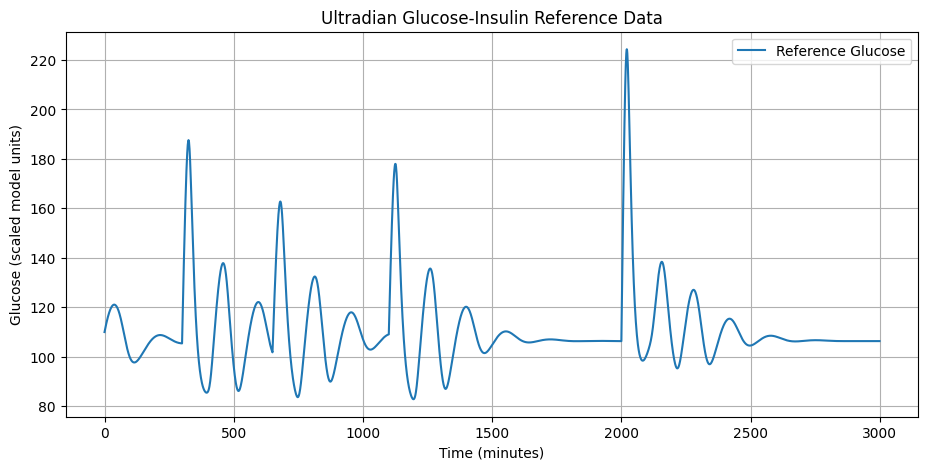

Dataset shape: (3000, 7)
Time range: 0.0 to 2999.0
First 5 rows:
[[0.00000000e+00 3.60000000e+01 4.40000000e+01 1.10000000e+04
  0.00000000e+00 0.00000000e+00 0.00000000e+00]
 [1.00000000e+00 3.87336828e+01 4.52364699e+01 1.10530060e+04
  2.99211162e+00 1.21424282e-01 3.32800913e-03]
 [2.00000000e+00 4.10789617e+01 4.66049468e+01 1.11051851e+04
  5.94719832e+00 4.71069977e-01 2.54963379e-02]
 [3.00000000e+00 4.31184271e+01 4.80790672e+01 1.11564712e+04
  8.84064653e+00 1.02667211e+00 8.23449699e-02]
 [4.00000000e+00 4.49168166e+01 4.96380169e+01 1.12068052e+04
  1.16556622e+01 1.76610906e+00 1.86668749e-01]]


In [2]:

import numpy as np
import matplotlib.pyplot as plt

# Load numerical reference data
data = np.loadtxt("glucose.dat")

time = data[:, 0]

# Third biological state is glucose
# Original reference implementation uses a scaling factor
glucose = data[:, 3] / 100.0

plt.figure(figsize=(11, 5))
plt.plot(time, glucose, label="Reference Glucose")

plt.xlabel("Time (minutes)")
plt.ylabel("Glucose (scaled model units)")
plt.title("Ultradian Glucose-Insulin Reference Data")
plt.grid(True)
plt.legend()
plt.show()

print("Dataset shape:", data.shape)
print("Time range:", time.min(), "to", time.max())
print("First 5 rows:")
print(data[:5])


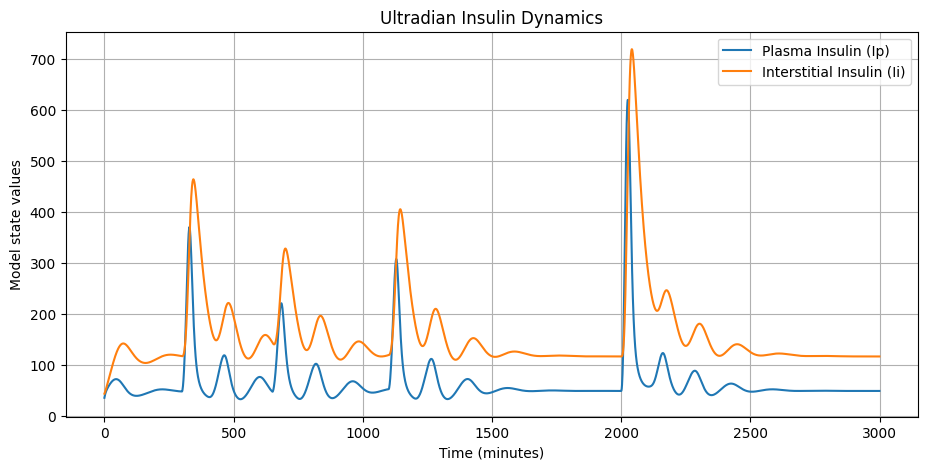

In [3]:

# Data columns:
# 0 = time
# 1 = plasma insulin (Ip)
# 2 = interstitial insulin (Ii)
# 3 = glucose (G)
# 4, 5, 6 = delay states

plt.figure(figsize=(11, 5))

plt.plot(time, data[:, 1], label="Plasma Insulin (Ip)")
plt.plot(time, data[:, 2], label="Interstitial Insulin (Ii)")

plt.xlabel("Time (minutes)")
plt.ylabel("Model state values")
plt.title("Ultradian Insulin Dynamics")
plt.legend()
plt.grid(True)
plt.show()


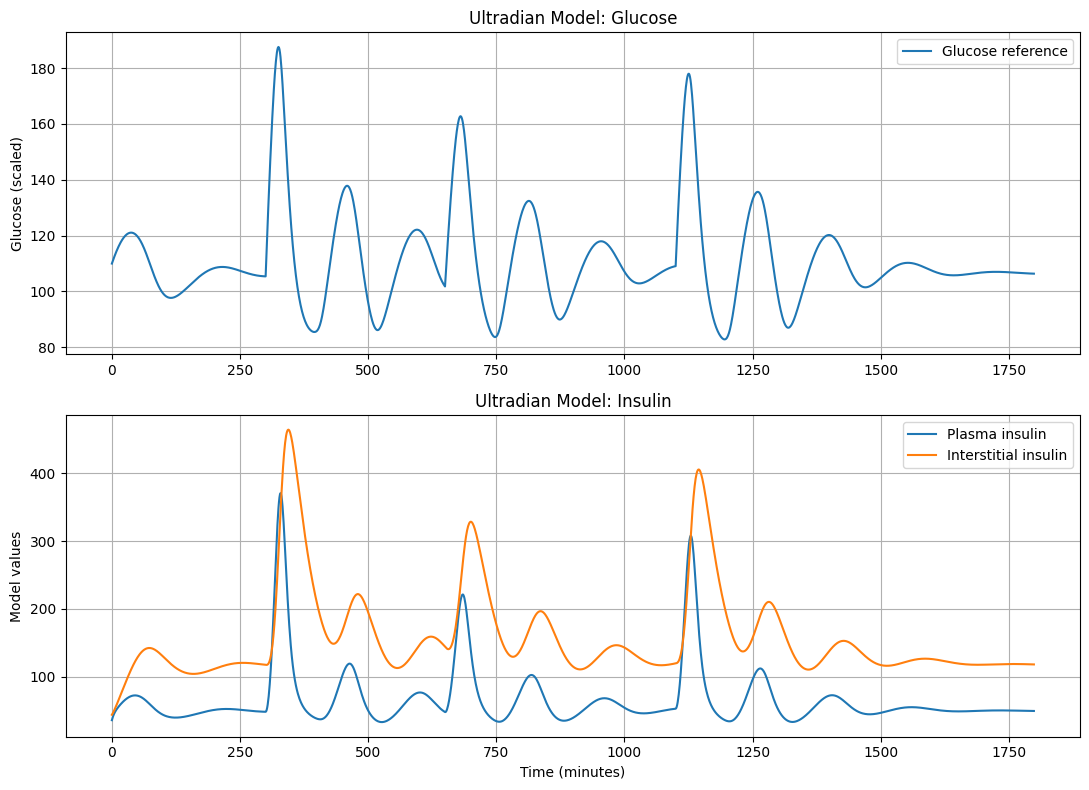

Training data shape: (1800, 7)
Glucose range: 82.84855340766501 187.5865193400797
NaN values: 0


In [4]:

import numpy as np
import matplotlib.pyplot as plt

data = np.loadtxt("/content/sbinn/sbinn/glucose.dat")

# First 1800 minutes for the training experiment
train_data = data[:1800]

t = train_data[:, 0]
Ip = train_data[:, 1]
Ii = train_data[:, 2]
G = train_data[:, 3] / 100.0

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

axes[0].plot(t, G, label="Glucose reference")
axes[0].set_title("Ultradian Model: Glucose")
axes[0].set_ylabel("Glucose (scaled)")
axes[0].grid(True)
axes[0].legend()

axes[1].plot(t, Ip, label="Plasma insulin")
axes[1].plot(t, Ii, label="Interstitial insulin")
axes[1].set_title("Ultradian Model: Insulin")
axes[1].set_xlabel("Time (minutes)")
axes[1].set_ylabel("Model values")
axes[1].grid(True)
axes[1].legend()

plt.tight_layout()
plt.savefig("ultradian_reference.png", dpi=200)
plt.show()

print("Training data shape:", train_data.shape)
print("Glucose range:", G.min(), G.max())
print("NaN values:", np.isnan(train_data).sum())


In [5]:
%cd /content/sbinn/sbinn
%pip install -q deepxde

/content/sbinn/sbinn


In [8]:

from pathlib import Path

file = Path("/content/sbinn/sbinn/sbinn_smoke_test.py")

code = file.read_text()

old = "torch.Tensor([1, 1, 1e2, 1, 1, 1])"
new = "y.new_tensor([1, 1, 1e2, 1, 1, 1])"

if old not in code:
    raise ValueError("Original tensor line not found!")

code = code.replace(old, new)

file.write_text(code)

print("GPU/CPU tensor mismatch fixed!")
print("Updated file:", file)


GPU/CPU tensor mismatch fixed!
Updated file: /content/sbinn/sbinn/sbinn_smoke_test.py


In [9]:

%cd /content/sbinn/sbinn

!DDE_BACKEND=pytorch python sbinn_smoke_test.py


/content/sbinn/sbinn
Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.
Compiling model...
'compile' took 1.372588 s

Training model...

Step      Train loss                                                                Test loss                                                                 Test metric
0         [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 2.98e+04]    [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 2.98e+04]    []  
20        [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 2.81e+04]    [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 2.81e+04]    []  
40        [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 2.40e+04]    [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 2.40e+04]    []  
60        [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 2.05e+04]    [0.00e+00, 0.00e+00, 

In [10]:

from pathlib import Path
import numpy as np

folder = Path("/content/sbinn/sbinn")

files = [
    "loss.dat",
    "train.dat",
    "test.dat",
    "variables.csv",
    "glucose_input.dat"
]

for name in files:
    path = folder / name
    print(f"\n--- {name} ---")

    if not path.exists():
        print("File not found")
        continue

    print("File size:", path.stat().st_size, "bytes")

    if name.endswith(".dat"):
        try:
            arr = np.loadtxt(path, comments="#")
            print("Shape:", arr.shape)
            print("First rows:")
            print(np.atleast_2d(arr)[:3])
        except Exception as e:
            print("Read error:", e)
    else:
        print("First 3 lines:")
        print("\n".join(
            path.read_text().splitlines()[:3]
        ))



--- loss.dat ---
File size: 4544 bytes
Shape: (12, 15)
First rows:
[[0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 2.97669397e+04
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 2.97669397e+04]
 [2.00000000e+01 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 2.80794813e+04
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 2.80794813e+04]
 [4.00000000e+01 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 0.00000000e+00 2.40267233e+04
  0.00000000e+00 0.00000000e+00 0.00000000e+00 0.00000000e+00
  0.00000000e+00 0.00000000e+00 2.40267233e+04]]

--- train.dat ---
File size: 54054 bytes
Shape: (2162,)
First rows:
[[1229.  305.  623. ... 1797. 1798. 1799.]]

--- test.dat ---
File size: 378432 bytes
Shape: (2162, 7)
First rows:
[[1.22900000e+03 3.49174033e+01 8.04316507e+0

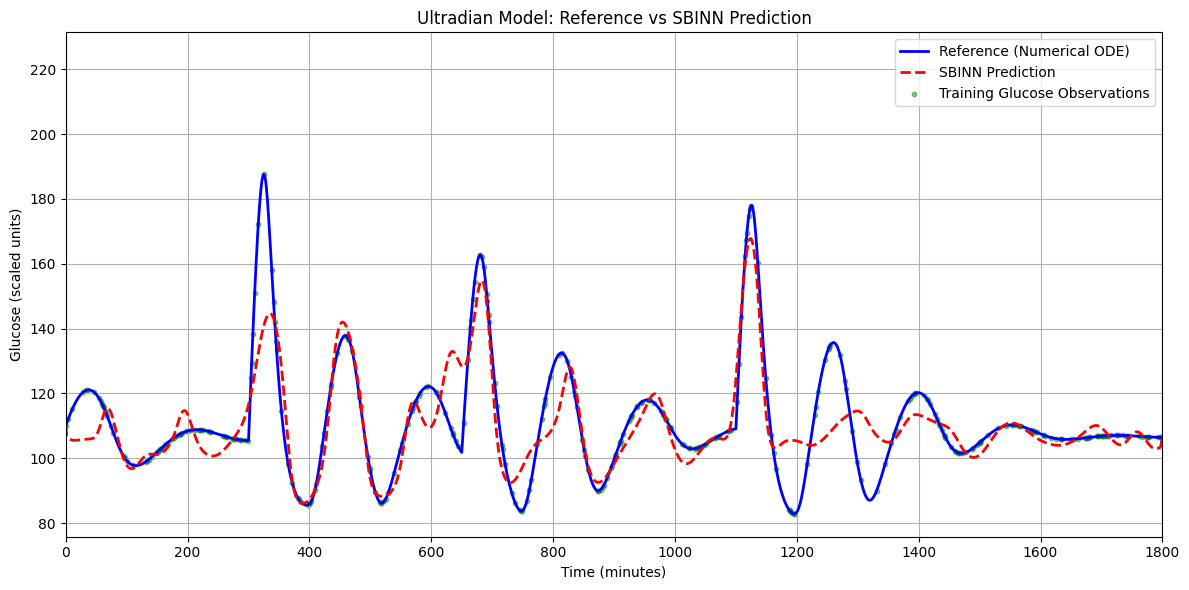

Comparison points: 1800
Glucose RMSE: 9.646400
Glucose MAE: 6.229746


In [11]:

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("/content/sbinn/sbinn")

# Numerical reference solution
reference = np.loadtxt(folder / "glucose.dat")

# Neural network predictions
predictions = np.loadtxt(folder / "test.dat")

# Glucose observations used during training
observations = np.loadtxt(folder / "glucose_input.dat")

# Column 0 = time, column 3 = glucose
t_true = reference[:, 0]
g_true = reference[:, 3] / 100.0

t_pred = predictions[:, 0]
g_pred = predictions[:, 3] / 100.0

t_obs = observations[:, 0]
g_obs = observations[:, 1] / 100.0

# Sort predictions by time for correct plotting
order = np.argsort(t_pred)
t_pred = t_pred[order]
g_pred = g_pred[order]

# Average predictions at duplicate time points, if any
unique_times, inverse = np.unique(
    t_pred, return_inverse=True
)
sums = np.bincount(inverse, weights=g_pred)
counts = np.bincount(inverse)
unique_predictions = sums / counts

# Match reference trajectory to prediction times
valid = (
    (unique_times >= t_true.min()) &
    (unique_times <= t_true.max())
)

t_comparison = unique_times[valid]
g_comparison = unique_predictions[valid]

g_reference_matched = np.interp(
    t_comparison, t_true, g_true
)

rmse = np.sqrt(
    np.mean((g_comparison - g_reference_matched) ** 2)
)

mae = np.mean(
    np.abs(g_comparison - g_reference_matched)
)

# Plot
plt.figure(figsize=(12, 6))

plt.plot(
    t_true, g_true,
    label="Reference (Numerical ODE)",
    color="blue", linewidth=2
)

plt.plot(
    t_comparison, g_comparison,
    label="SBINN Prediction",
    color="red", linestyle="--", linewidth=2
)

plt.scatter(
    t_obs, g_obs,
    label="Training Glucose Observations",
    color="green", s=10, alpha=0.45
)

plt.xlim(0, 1800)
plt.xlabel("Time (minutes)")
plt.ylabel("Glucose (scaled units)")
plt.title("Ultradian Model: Reference vs SBINN Prediction")
plt.legend()
plt.grid(True)
plt.tight_layout()

plt.savefig(
    "/content/glucose_comparison.png",
    dpi=200
)
plt.show()

print("Comparison points:", len(t_comparison))
print(f"Glucose RMSE: {rmse:.6f}")
print(f"Glucose MAE: {mae:.6f}")


In [12]:

from pathlib import Path

source = Path("/content/sbinn/sbinn/sbinn_smoke_test.py")
target = Path("/content/sbinn/sbinn/sbinn_experiment_1.py")

code = source.read_text()

# Confirm existing short-training settings
for old in [
    "firsttrain = 100",
    "maxepochs = 100",
]:
    if old not in code:
        raise ValueError(f"Setting not found: {old}")

# Increase training iterations
code = code.replace(
    "firsttrain = 100",
    "firsttrain = 1000"
)

code = code.replace(
    "maxepochs = 100",
    "maxepochs = 3000"
)

# Print intermediate results less frequently
code = code.replace(
    "display_every=20",
    "display_every=500"
)

target.write_text(code)

print("Experiment file created:", target)


Experiment file created: /content/sbinn/sbinn/sbinn_experiment_1.py


In [13]:

%cd /content/sbinn/sbinn
!DDE_BACKEND=pytorch python sbinn_experiment_1.py


/content/sbinn/sbinn
Using backend: pytorch
Other supported backends: tensorflow.compat.v1, tensorflow, jax, paddle.
paddle supports more examples now and is recommended.
Compiling model...
'compile' took 1.159066 s

Training model...

Step      Train loss                                                                Test loss                                                                 Test metric
0         [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 3.07e+04]    [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 3.07e+04]    []  
500       [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 1.95e+02]    [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 1.95e+02]    []  
1000      [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 1.99e+01]    [0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 0.00e+00, 1.99e+01]    []  

Best model at step 1000:
  train loss: 1.99e+01
  test loss: 1.99e+01
  test metric: []

'train' took 34

In [14]:

import os
import variable_to_parameter_transform

os.chdir("/content/sbinn/sbinn")

# Convert parameters from the completed 4000-step run
variable_to_parameter_transform.variable_file(
    1000, 20, 3000, "variables.csv"
)

print("Parameter conversion completed!")


Parameter conversion completed!


In [15]:

import shutil

shutil.make_archive(
    "/content/SBINN_4000_steps",
    "zip",
    "/content/sbinn/sbinn"
)

from google.colab import files
files.download("/content/SBINN_4000_steps.zip")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [16]:
import numpy as np

folder = "/content/sbinn/sbinn/"

reference = np.loadtxt(folder + "glucose.dat")
predictions = np.loadtxt(folder + "test.dat")

t_ref = reference[:, 0]
g_ref = reference[:, 3] / 100.0

t_pred = predictions[:, 0]
g_pred = predictions[:, 3] / 100.0

# Match predictions to reference times
g_true = np.interp(t_pred, t_ref, g_ref)

rmse = np.sqrt(np.mean((g_pred - g_true)**2))
mae = np.mean(np.abs(g_pred - g_true))

print("4000-step Glucose RMSE:", rmse)
print("4000-step Glucose MAE:", mae)

4000-step Glucose RMSE: 0.7099091546584876
4000-step Glucose MAE: 0.33341975613865604


In [17]:
import os
import variable_to_parameter_transform

os.chdir("/content/sbinn/sbinn")

variable_to_parameter_transform.variable_file(
    1000, 20, 3000, "variables.csv"
)

In [18]:

import pandas as pd
from pathlib import Path

folder = Path("/content/sbinn/sbinn")
file = folder / "varlist.csv"

if not file.exists():
    raise FileNotFoundError("varlist.csv not found")

df = pd.read_csv(file)

print("Shape:", df.shape)
print("\nAvailable columns:")
print(df.columns.tolist())

print("\nFinal estimated parameters:")
print(df.tail(1).T.to_string(header=False))


Shape: (151, 18)

Available columns:
['Epoch', 'E', 'tp', 'ti', 'td', 'k', 'Rm', 'a1', 'C1', 'C2', 'C4', 'C5', 'Ub', 'U0', 'Um', 'Rg', 'alpha', 'beta']

Final estimated parameters:
Epoch  4000.000000
E         0.217614
tp        6.628042
ti      117.849744
td       15.214822
k         0.002278
Rm      139.977298
a1        6.600000
C1      300.000000
C2      144.000000
C4       97.702599
C5       24.345741
Ub       84.690848
U0        4.759629
Um       78.296736
Rg      302.946862
alpha    12.572734
beta      1.452928


In [19]:

import numpy as np
import pandas as pd

true_params = {
    "E": 0.2,
    "tp": 6,
    "ti": 100,
    "td": 12,
    "k": 0.0083,
    "Rm": 209,
    "a1": 6.6,
    "C1": 300,
    "C2": 144,
    "C4": 80,
    "C5": 26,
    "Ub": 72,
    "U0": 4,
    "Um": 90,
    "Rg": 180,
    "alpha": 7.5,
    "beta": 1.772
}

final = df.iloc[-1]

results = []

for name, true_value in true_params.items():
    estimated = float(final[name])

    error = (
        abs(estimated - true_value)
        / abs(true_value)
        * 100
    )

    results.append({
        "Parameter": name,
        "True Value": true_value,
        "Estimated Value": estimated,
        "Error (%)": error
    })

comparison = pd.DataFrame(results)

print("\nINVERSE PARAMETER ESTIMATION RESULTS\n")
print(comparison.round(5).to_string(index=False))

print("\nMean Absolute Percentage Error:",
      round(comparison["Error (%)"].mean(), 3), "%")

comparison.to_csv(
    "/content/sbinn_parameter_comparison.csv",
    index=False
)



INVERSE PARAMETER ESTIMATION RESULTS

Parameter  True Value  Estimated Value  Error (%)
        E      0.2000          0.21761    8.80718
       tp      6.0000          6.62804   10.46736
       ti    100.0000        117.84974   17.84974
       td     12.0000         15.21482   26.79018
        k      0.0083          0.00228   72.55512
       Rm    209.0000        139.97730   33.02522
       a1      6.6000          6.60000    0.00000
       C1    300.0000        300.00000    0.00000
       C2    144.0000        144.00000    0.00000
       C4     80.0000         97.70260   22.12825
       C5     26.0000         24.34574    6.36253
       Ub     72.0000         84.69085   17.62618
       U0      4.0000          4.75963   18.99072
       Um     90.0000         78.29674   13.00363
       Rg    180.0000        302.94686   68.30381
    alpha      7.5000         12.57273   67.63645
     beta      1.7720          1.45293   18.00634

Mean Absolute Percentage Error: 23.621 %


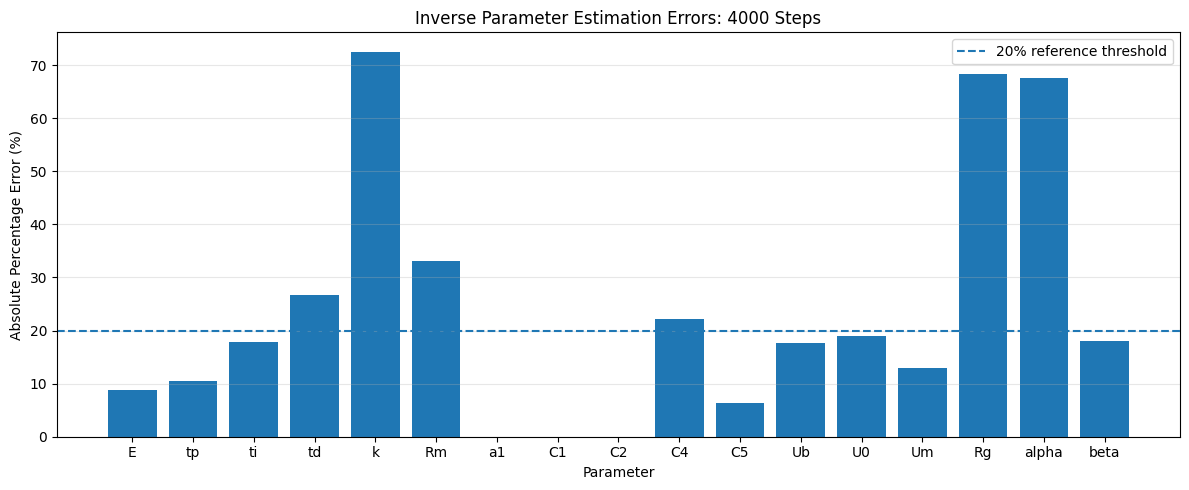


PARAMETER DEFINITIONS IN TRAINING CODE

Line 14: E_ = dde.Variable(0.0)
Line 15: tp_ = dde.Variable(0.0)
Line 16: ti_ = dde.Variable(0.0)
Line 17: td_ = dde.Variable(0.0)
Line 18: k_ = dde.Variable(0.0)
Line 19: Rm_ = dde.Variable(0.0)
Line 20: a1_ = dde.Variable(0.0)
Line 21: C1_ = dde.Variable(0.0)
Line 22: C2_ = dde.Variable(0.0)
Line 23: C4_ = dde.Variable(0.0)
Line 24: C5_ = dde.Variable(0.0)
Line 25: Ub_ = dde.Variable(0.0)
Line 26: U0_ = dde.Variable(0.0)
Line 27: Um_ = dde.Variable(0.0)
Line 28: Rg_ = dde.Variable(0.0)
Line 29: alpha_ = dde.Variable(0.0)
Line 30: beta_ = dde.Variable(0.0)
Line 69: a1 = get_variable(6.6, a1_)
Line 70: C1 = get_variable(300 / 100, C1_)
Line 71: C2 = get_variable(144 / 100, C2_)
Line 173: external_trainable_variables=var_list_,


In [20]:

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

folder = Path("/content/sbinn/sbinn")

# Read your existing comparison
comparison = pd.read_csv(
    "/content/sbinn_parameter_comparison.csv"
)

# Plot errors
plt.figure(figsize=(12, 5))
plt.bar(
    comparison["Parameter"],
    comparison["Error (%)"]
)
plt.axhline(
    20, linestyle="--",
    label="20% reference threshold"
)
plt.ylabel("Absolute Percentage Error (%)")
plt.xlabel("Parameter")
plt.title("Inverse Parameter Estimation Errors: 4000 Steps")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()

plt.savefig(
    "/content/inverse_parameter_errors.png",
    dpi=200
)
plt.show()

# Inspect parameter definitions in actual model
script = (
    folder / "sbinn_experiment_1.py"
).read_text().splitlines()

print("\nPARAMETER DEFINITIONS IN TRAINING CODE\n")

keywords = [
    "dde.Variable",
    "external_trainable_variables",
    "a1 =",
    "C1 =",
    "C2 ="
]

for i, line in enumerate(script, start=1):
    if any(word in line for word in keywords):
        print(f"Line {i}: {line.strip()}")


In [21]:

import pandas as pd
import numpy as np

df = pd.read_csv(
    "/content/sbinn/sbinn/varlist.csv"
)

parameters = [
    c for c in df.columns if c != "Epoch"
]

initial = df.iloc[0]
final = df.iloc[-1]

print("PARAMETER CHANGE ANALYSIS\n")

for p in parameters:
    start = float(initial[p])
    end = float(final[p])
    change = end - start

    print(
        f"{p:8s} | "
        f"Start: {start:12.6f} | "
        f"Final: {end:12.6f} | "
        f"Change: {change:+.6f}"
    )

print("\nUnchanged parameters:")
for p in parameters:
    if np.isclose(
        initial[p], final[p],
        rtol=1e-8, atol=1e-8
    ):
        print(p)


PARAMETER CHANGE ANALYSIS

E        | Start:     0.200000 | Final:     0.217614 | Change: +0.017614
tp       | Start:     6.000000 | Final:     6.628042 | Change: +0.628042
ti       | Start:   100.000000 | Final:   117.849744 | Change: +17.849744
td       | Start:    12.500000 | Final:    15.214822 | Change: +2.714822
k        | Start:     0.008300 | Final:     0.002278 | Change: -0.006022
Rm       | Start:   209.000000 | Final:   139.977298 | Change: -69.022702
a1       | Start:     6.600000 | Final:     6.600000 | Change: +0.000000
C1       | Start:   300.000000 | Final:   300.000000 | Change: +0.000000
C2       | Start:   144.000000 | Final:   144.000000 | Change: +0.000000
C4       | Start:    80.000000 | Final:    97.702599 | Change: +17.702599
C5       | Start:    26.000000 | Final:    24.345741 | Change: -1.654259
Ub       | Start:    72.000000 | Final:    84.690848 | Change: +12.690848
U0       | Start:     4.000000 | Final:     4.759629 | Change: +0.759629
Um       | Start:   

In [22]:

import pandas as pd
import numpy as np
from pathlib import Path

folder = Path("/content/sbinn/sbinn")

# Correct reference value for this implementation
comparison = pd.read_csv(
    "/content/sbinn_parameter_comparison.csv"
)

comparison.loc[
    comparison["Parameter"] == "td", "True Value"
] = 12.5

comparison["Error (%)"] = (
    abs(
        comparison["Estimated Value"]
        - comparison["True Value"]
    )
    / comparison["True Value"]
    * 100
)

# Check raw parameter values
import re

raw_lines = (folder / "variables.csv").read_text().splitlines()

print("RAW TRAINABLE VARIABLES")
print("Epoch | a1_ | C1_ | C2_")

for line in [raw_lines[0], raw_lines[len(raw_lines)//2], raw_lines[-1]]:
    step = int(line.split("[")[0].strip())
    values = np.fromstring(
        line.split("[", 1)[1].split("]")[0],
        sep=","
    )
    print(step, values[6], values[7], values[8])

print("\nCORRECTED PARAMETER ERRORS")
print(comparison.round(4).to_string(index=False))

print("\nMAPE across all 17:",
      round(comparison["Error (%)"].mean(), 3), "%")

changed = comparison[
    ~comparison["Parameter"].isin(["a1", "C1", "C2"])
]

print("MAPE across 14 changed parameters:",
      round(changed["Error (%)"].mean(), 3), "%")

comparison.to_csv(
    "/content/sbinn_parameter_comparison_corrected.csv",
    index=False
)


RAW TRAINABLE VARIABLES
Epoch | a1_ | C1_ | C2_
1000 0.0 0.0 0.0
2500 0.0 0.0 0.0
4000 0.0 0.0 0.0

CORRECTED PARAMETER ERRORS
Parameter  True Value  Estimated Value  Error (%)
        E      0.2000           0.2176     8.8072
       tp      6.0000           6.6280    10.4674
       ti    100.0000         117.8497    17.8497
       td     12.5000          15.2148    21.7186
        k      0.0083           0.0023    72.5551
       Rm    209.0000         139.9773    33.0252
       a1      6.6000           6.6000     0.0000
       C1    300.0000         300.0000     0.0000
       C2    144.0000         144.0000     0.0000
       C4     80.0000          97.7026    22.1282
       C5     26.0000          24.3457     6.3625
       Ub     72.0000          84.6908    17.6262
       U0      4.0000           4.7596    18.9907
       Um     90.0000          78.2967    13.0036
       Rg    180.0000         302.9469    68.3038
    alpha      7.5000          12.5727    67.6364
     beta      1.7720  